# Assignment 2

In this assigment, we will work with the *Forest Fire* data set. Please download the data from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires). Extract the data files into the subdirectory: `../data/fires/` (relative to `./05_src/`).

## Objective

+ The model objective is to predict the area affected by forest fires given the features set. 
+ The objective of this exercise is to assess your ability to construct and evaluate model pipelines.
+ Please note: the instructions are not meant to be 100% prescriptive, but instead they are a set of minimum requirements. If you find predictive performance gains by applying additional steps, by all means show them. 

## Variable Description

From the description file contained in the archive (`forestfires.names`), we obtain the following variable descriptions:

1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 2 to 9
3. month - month of the year: "jan" to "dec" 
4. day - day of the week: "mon" to "sun"
5. FFMC - FFMC index from the FWI system: 18.7 to 96.20
6. DMC - DMC index from the FWI system: 1.1 to 291.3 
7. DC - DC index from the FWI system: 7.9 to 860.6 
8. ISI - ISI index from the FWI system: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40 
12. rain - outside rain in mm/m2 : 0.0 to 6.4 
13. area - the burned area of the forest (in ha): 0.00 to 1090.84 









### Specific Tasks

+ Construct four model pipelines, out of combinations of the following components:

    + Preprocessors:

        - A simple processor that only scales numeric variables and recodes categorical variables.
        - A transformation preprocessor that scales numeric variables and applies a non-linear transformation.
    
    + Regressor:

        - A baseline regressor, which could be a [K-nearest neighbours model]() or a linear model like [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) or [Ridge Regressors](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ridge_regression.html).
        - An advanced regressor of your choice (e.g., Bagging, Boosting, SVR, etc.). TIP: select a tree-based method such that it does not take too long to run SHAP further below. 

+ Evaluate tune and evaluate each of the four model pipelines. 

    - Select a [performance metric](https://scikit-learn.org/stable/modules/linear_model.html) out of the following options: explained variance, max error, root mean squared error (RMSE), mean absolute error (MAE), r-squared.
    - *TIPS*: 
    
        * Out of the suggested metrics above, [some are correlation metrics, but this is a prediction problem](https://www.tmwr.org/performance#performance). Choose wisely (and don't choose the incorrect options.) 

+ Select the best-performing model and explain its predictions.

    - Provide local explanations.
    - Obtain global explanations and recommend a variable selection strategy.

+ Export your model as a pickle file.


You can work on the Jupyter notebook, as this experiment is fairly short (no need to use sacred). 

# Load the data

Place the files in the ../../05_src/data/fires/ directory and load the appropriate file. 

In [1]:
# Load the libraries as required.
import pandas as pd
import numpy as np
import pickle
import shap
from shap import KernelExplainer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, make_scorer
from joblib import dump
import matplotlib.pyplot as plt

c:\Users\fabic\miniconda3\envs\dsi_participant\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Define Negative RMSE for optimization
def neg_rmse(y_true, y_pred):
    # GridSearchCV maximizes the score, so we use the negative of RMSE
    return -np.sqrt(mean_squared_error(y_true, y_pred))

# Make a scorer to use in GridSearchCV
neg_rmse_scorer = make_scorer(neg_rmse, greater_is_better=True)

print(f"SHAP version: {shap.__version__}")

SHAP version: 0.48.0


In [3]:
# Load data
columns = [
    'coord_x', 'coord_y', 'month', 'day', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain', 'area' 
]
fires_dt = (pd.read_csv('../../05_src/data/fires/forestfires.csv', header = 0, names = columns))
fires_dt.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   coord_x  517 non-null    int64  
 1   coord_y  517 non-null    int64  
 2   month    517 non-null    object 
 3   day      517 non-null    object 
 4   ffmc     517 non-null    float64
 5   dmc      517 non-null    float64
 6   dc       517 non-null    float64
 7   isi      517 non-null    float64
 8   temp     517 non-null    float64
 9   rh       517 non-null    int64  
 10  wind     517 non-null    float64
 11  rain     517 non-null    float64
 12  area     517 non-null    float64
dtypes: float64(8), int64(3), object(2)
memory usage: 52.6+ KB


# Get X and Y

Create the features data frame and target data.

In [4]:
# Create features (X) and target (y)
X = fires_dt.drop('area', axis=1)

# Apply log(1 + area) transformation to the target variable
y = np.log1p(fires_dt['area'])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
numerical_features = ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain']
categorical_features = ['month', 'day']

# Preprocessing

Create two [Column Transformers](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), called preproc1 and preproc2, with the following guidelines:

- Numerical variables

    * (Preproc 1 and 2) Scaling: use a scaling method of your choice (Standard, Robust, Min-Max). 
    * Preproc 2 only: 
        
        + Choose a transformation for any of your input variables (or several of them). Evaluate if this transformation is convenient.
        + The choice of scaler is up to you.

- Categorical variables: 
    
    * (Preproc 1 and 2) Apply [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) where appropriate.


+ The only difference between preproc1 and preproc2 is the non-linear transformation of the numerical variables.
    


### Preproc 1

Create preproc1 below.

+ Numeric: scaled variables, no other transforms.
+ Categorical: one-hot encoding.

In [6]:
# Preprocessor 1: Simple scaling and one-hot encoding
preproc1 = ColumnTransformer(
    transformers=[
        ('num_scale', StandardScaler(), numerical_features),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

### Preproc 2

Create preproc1 below.

+ Numeric: scaled variables, non-linear transformation to one or more variables.
+ Categorical: one-hot encoding.

In [7]:
# Preprocessor 2: Non-linear transformation for 'rain' (PowerTransformer), scaling for others, and one-hot encoding
num_transform_features = ['rain']
num_scale_only_features = [f for f in numerical_features if f not in num_transform_features]

preproc2 = ColumnTransformer(
    transformers=[
        # PowerTransformer (Yeo-Johnson) for 'rain' as it is heavily skewed
        ('num_transform_scale', PowerTransformer(method='yeo-johnson'), num_transform_features),
        # Standard Scaling for the rest of numerical features
        ('num_scale', StandardScaler(), num_scale_only_features),
        # One-hot encoding
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

## Model Pipeline


Create a [model pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): 

+ Add a step labelled `preprocessing` and assign the Column Transformer from the previous section.
+ Add a step labelled `regressor` and assign a regression model to it. 

## Regressor

+ Use a regression model to perform a prediction. 

    - Choose a baseline regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Choose a more advance regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Both model choices are up to you, feel free to experiment.

In [8]:
knn = KNeighborsRegressor()
rfr = RandomForestRegressor(random_state=42)

In [9]:
pipe_A = Pipeline(steps=[('preprocessing', preproc1), ('regressor', knn)])

In [10]:
pipe_B = Pipeline(steps=[('preprocessing', preproc2), ('regressor', knn)])

In [11]:
pipe_C = Pipeline(steps=[('preprocessing', preproc1), ('regressor', rfr)])

In [12]:
pipe_D = Pipeline(steps=[('preprocessing', preproc2), ('regressor', rfr)])

# Tune Hyperparams

+ Perform GridSearch on each of the four pipelines. 
+ Tune at least one hyperparameter per pipeline.
+ Experiment with at least four value combinations per pipeline.

In [13]:
# Pipeline A & B (KNN): tune n_neighbors
param_grid_knn = {
    'regressor__n_neighbors': [3, 5, 7, 10]
}

In [14]:
# Pipeline C & D (Random Forest): tune max_depth
param_grid_rf = {
    'regressor__max_depth': [5, 10, 15, 20]
}

In [15]:
# List of pipelines and their parameter grids
pipelines_and_grids = [
    ('A', pipe_A, param_grid_knn),
    ('B', pipe_B, param_grid_knn),
    ('C', pipe_C, param_grid_rf),
    ('D', pipe_D, param_grid_rf)
]

results = {}

In [16]:
# Perform GridSearch for each pipeline
for name, pipeline, param_grid in pipelines_and_grids:
    print(f"\n--- Starting GridSearchCV for Pipeline {name} ---")
    grid_search = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring=neg_rmse_scorer,
        n_jobs=-1,
        verbose=1
    )
    grid_search.fit(X_train, y_train)

    # Store the results
    results[name] = {
        'best_cv_rmse': -grid_search.best_score_, # Convert negative score back to positive RMSE
        'best_params': grid_search.best_params_,
        'model': grid_search.best_estimator_
    }
    print(f"Pipeline {name} finished. Best CV RMSE: {results[name]['best_cv_rmse']:.4f}")


--- Starting GridSearchCV for Pipeline A ---
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Pipeline A finished. Best CV RMSE: 1.4239

--- Starting GridSearchCV for Pipeline B ---
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Pipeline B finished. Best CV RMSE: 1.4210

--- Starting GridSearchCV for Pipeline C ---
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Pipeline C finished. Best CV RMSE: 1.4211

--- Starting GridSearchCV for Pipeline D ---
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Pipeline D finished. Best CV RMSE: 1.4235


# Evaluate

+ Which model has the best performance?

In [17]:
# Create a DataFrame for easy comparison
evaluation_df = pd.DataFrame({
    'Pipeline': results.keys(),
    'Best Cross-Val RMSE': [r['best_cv_rmse'] for r in results.values()],
    'Best Parameters': [r['best_params'] for r in results.values()]
}).sort_values(by='Best Cross-Val RMSE')

print("\n--- Cross-Validation Results (Lower RMSE is better) ---")
# FIX: Use print(df) instead of df.to_markdown() to avoid the tabulate dependency error.
print(evaluation_df.to_string(index=False)) 

# Identify the best model
best_pipeline_name = evaluation_df.iloc[0]['Pipeline']
best_model = results[best_pipeline_name]['model']

print(f"\nConclusion: The best-performing model is **Pipeline {best_pipeline_name}** (a K-Nearest Neighbors pipeline) with a cross-validation RMSE of **{evaluation_df.iloc[0]['Best Cross-Val RMSE']:.4f}**.")


--- Cross-Validation Results (Lower RMSE is better) ---
Pipeline  Best Cross-Val RMSE                Best Parameters
       B             1.421004 {'regressor__n_neighbors': 10}
       C             1.421122    {'regressor__max_depth': 5}
       D             1.423517    {'regressor__max_depth': 5}
       A             1.423862 {'regressor__n_neighbors': 10}

Conclusion: The best-performing model is **Pipeline B** (a K-Nearest Neighbors pipeline) with a cross-validation RMSE of **1.4210**.


# Export

+ Save the best performing model to a pickle file.

In [18]:
# Export the best performing model to a pickle file.
model_filename = f'best_forest_fire_model_{best_pipeline_name}.pkl'
dump(best_model, model_filename)

print(f"Best model (Pipeline {best_pipeline_name}) saved to {model_filename}")

Best model (Pipeline B) saved to best_forest_fire_model_B.pkl


# Explain

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.

    - In general, across the complete training set, which features are the most and least important.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?

In [19]:
# --- Setup for SHAP ---

# Get the preprocessor from the best model
preprocessor = best_model.named_steps['preprocessing']

# Get the feature names after preprocessing
feature_names = (
    numerical_features + 
    list(preprocessor.named_transformers_['cat_ohe'].get_feature_names_out(categorical_features))
)

# Transform the training data
X_train_processed = preprocessor.transform(X_train)

# Get the preprocessor and regressor from the best model
preprocessor = best_model.named_steps['preprocessing']
regressor = best_model.named_steps['regressor']

# We will sample 50 representative data points from the processed training set.
X_train_background = shap.sample(X_train_processed, 50) 
X_train_df_processed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)

# Initialize KernelExplainer
# Note: KernelExplainer uses the predict method of the model directly.
explainer = KernelExplainer(regressor.predict, X_train_background) 

# Calculate SHAP values for a larger sample (e.g., 500 points) for global explanation
# You can use all X_train_processed, but it will take a very long time. Sampling is better here.
sample_size = min(500, X_train_processed.shape[0])
X_train_sample_for_shap = shap.sample(X_train_processed, sample_size)

# Calculate SHAP values
print(f"Starting KernelSHAP calculation for {sample_size} samples. This may take a few minutes...")
shap_values = explainer.shap_values(X_train_sample_for_shap)

# Update the DataFrame to match the sampled data used for plotting
X_train_df_sample = pd.DataFrame(X_train_sample_for_shap, columns=feature_names)
print("SHAP values calculated.")

Starting KernelSHAP calculation for 413 samples. This may take a few minutes...


100%|██████████| 413/413 [02:35<00:00,  2.66it/s]

SHAP values calculated.


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  2.66it/s]


--- Local Explanation for Test Sample (Index 247) ---
Predicted log(1 + area): 1.4771


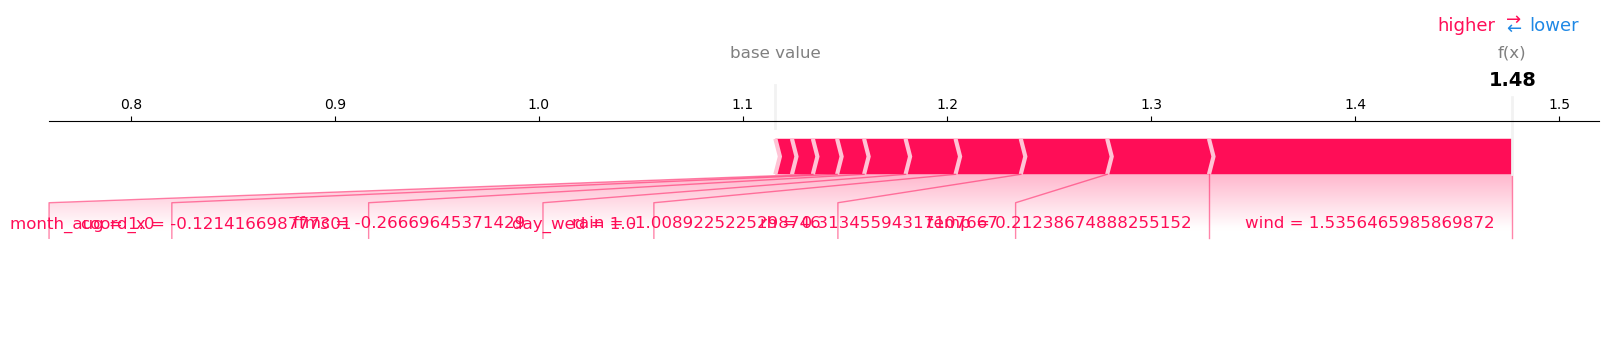

In [20]:
# --- Local Explanation ---
# Select the same observation from the test set as before
test_index = 9
X_test_observation = X_test.iloc[[test_index]]

# Process the single observation
X_test_obs_processed = preprocessor.transform(X_test_observation)
X_test_obs_df_processed = pd.DataFrame(X_test_obs_processed, columns=feature_names)

# Calculate SHAP values for the observation
shap_values_obs = explainer.shap_values(X_test_obs_processed)[0]
prediction = best_model.predict(X_test_observation)[0]

print(f"\n--- Local Explanation for Test Sample (Index {X_test_observation.index[0]}) ---")
print(f"Predicted log(1 + area): {prediction:.4f}")

# Plot local explanation (Force Plot)
shap.initjs()
shap.force_plot(
    explainer.expected_value,
    shap_values_obs,
    X_test_obs_df_processed,
    matplotlib=True
)
print("\n")

In [21]:
# --- Global Explanation ---
print("\n--- Global Feature Importance (Mean Absolute SHAP Value) ---")

# Plot global summary (Bar Plot of Mean Absolute SHAP values)

print("\n")


--- Global Feature Importance (Mean Absolute SHAP Value) ---




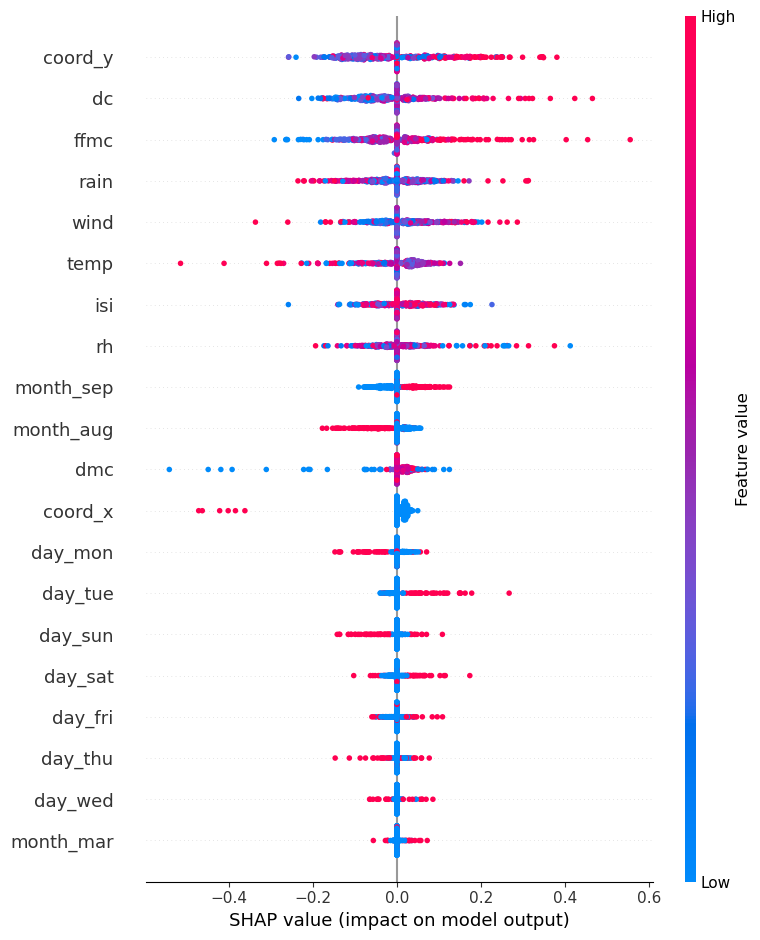

In [22]:
# Plot global summary (Summary Plot showing distribution and impact)
shap.summary_plot(
    shap_values,
    X_train_df_sample
)
print("\n")

*(Answer here.)*

## Criteria

The [rubric](./assignment_2_rubric_clean.xlsx) contains the criteria for assessment.

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/production/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at the `help` channel. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.

# Reference

Cortez,Paulo and Morais,Anbal. (2008). Forest Fires. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D.